# Machine Learning - Practical Session 5
## Feature Selection: Filter and Wrapper Methods

### Part A - Data Inspection and Baseline

In [1]:
# importing needed stuff
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest,
    f_classif,
    mutual_info_classif,
    SequentialFeatureSelector,
    RFE,
    RFECV
)

# loading breast cancer dataset
data = load_breast_cancer(as_frame=True)
df = data.frame
X = data.data
y = data.target

# basic checks
print('shape', df.shape)
print('missing values', df.isna().sum().sum())
print('duplicated rows', df.duplicated().sum())
print(df.dtypes.value_counts())
display(df.describe().T[['mean', 'std', 'min', 'max']].head(10))


shape (569, 31)
missing values 0
duplicated rows 0
float64    30
int64       1
Name: count, dtype: int64


,mean,std,min,max
mean radius,14.127292,3.524049,6.98100,28.11000
mean texture,19.289649,4.301036,9.71000,39.28000
mean perimeter,91.969033,24.298981,43.79000,188.50000
mean area,654.889104,351.914129,143.50000,2501.00000
mean smoothness,0.096360,0.014064,0.05263,0.16340
mean compactness,0.104341,0.052813,0.01938,0.34540
mean concavity,0.088799,0.079720,0.00000,0.42680
mean concave points,0.048919,0.038803,0.00000,0.20120
mean symmetry,0.181162,0.027414,0.10600,0.30400
mean fractal dimension,0.062798,0.007060,0.04996,0.09744


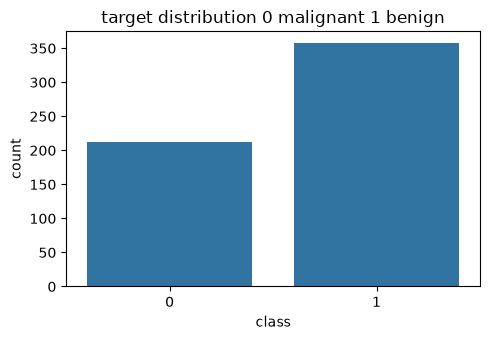

dummy test accuracy 0.6257


,Method,Nb features,Train accuracy,Test accuracy,Test F1-score,Time (s)
0,Baseline (all features),30,0.9874,0.9883,0.9907,0.00601


In [2]:
# target class distribution
plt.figure(figsize=(5, 3.5))
sns.countplot(x=y)
plt.title('target distribution 0 malignant 1 benign')
plt.xlabel('class')
plt.ylabel('count')
plt.tight_layout()
plt.show()

# fixed 70 30 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

# dummy baseline
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
dummy_acc = accuracy_score(y_test, dummy.predict(X_test))
print('dummy test accuracy', round(dummy_acc, 4))

# scaling train only
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# baseline logistic regression on all 30 features
t0 = time.perf_counter()
clf_base = LogisticRegression(max_iter=1000, random_state=42)
clf_base.fit(X_train_scaled, y_train)
train_time_base = time.perf_counter() - t0

y_train_pred = clf_base.predict(X_train_scaled)
y_test_pred = clf_base.predict(X_test_scaled)

baseline_row = pd.DataFrame([{
    'Method': 'Baseline (all features)',
    'Nb features': 30,
    'Train accuracy': round(accuracy_score(y_train, y_train_pred), 4),
    'Test accuracy': round(accuracy_score(y_test, y_test_pred), 4),
    'Test F1-score': round(f1_score(y_test, y_test_pred), 4),
    'Time (s)': round(train_time_base, 5)
}])
display(baseline_row)


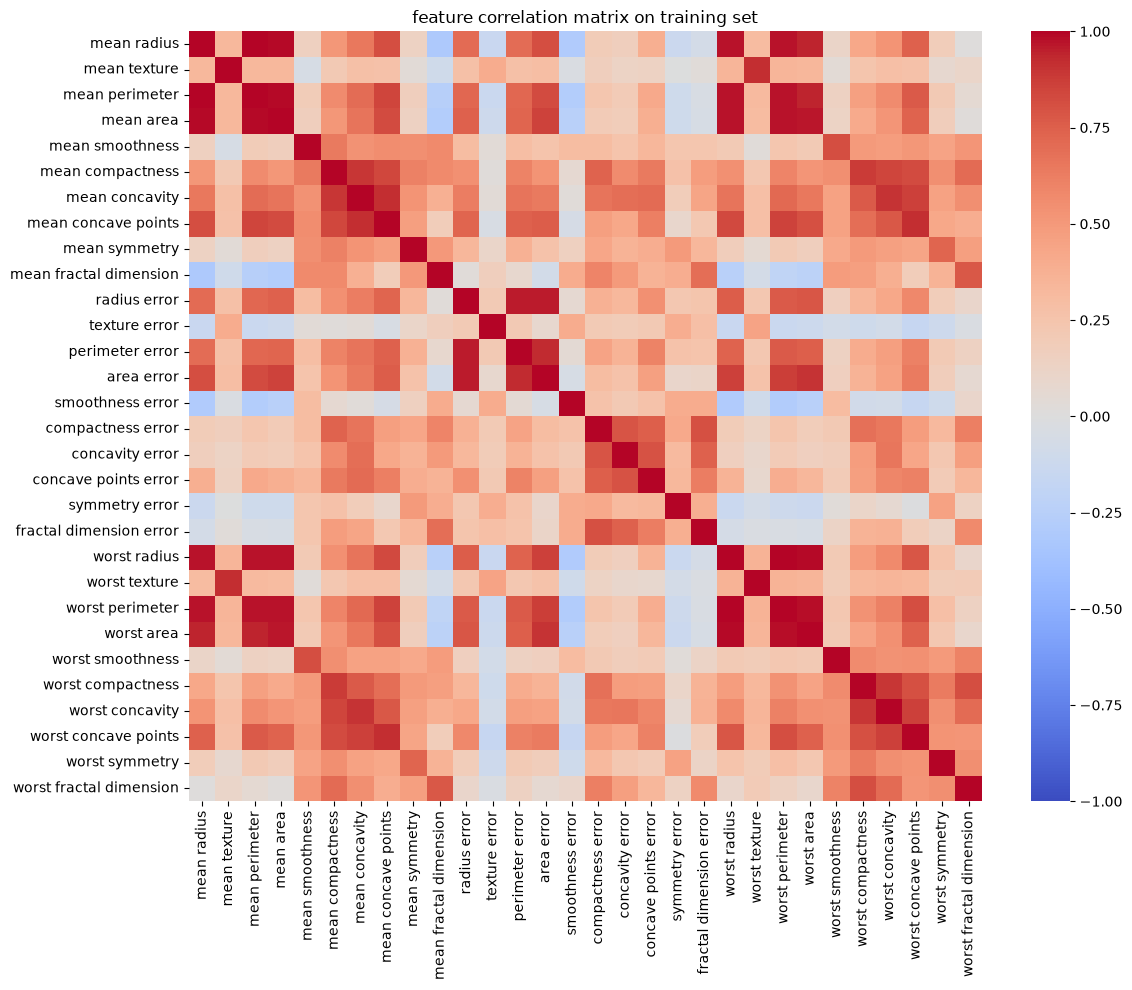

redundant pairs with abs corr > 0.95:
mean radius <-> mean perimeter: 0.9978
mean radius <-> mean area: 0.9906
mean radius <-> worst radius: 0.974
mean radius <-> worst perimeter: 0.9698
mean perimeter <-> mean area: 0.9895
mean perimeter <-> worst radius: 0.9736
mean perimeter <-> worst perimeter: 0.9749
mean area <-> worst radius: 0.974
mean area <-> worst perimeter: 0.9703
mean area <-> worst area: 0.9644
radius error <-> perimeter error: 0.9603
radius error <-> area error: 0.9544
worst radius <-> worst perimeter: 0.9934
worst radius <-> worst area: 0.986
worst perimeter <-> worst area: 0.9785


In [3]:
# correlation heatmap on training features
corr_matrix = X_train.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('feature correlation matrix on training set')
plt.tight_layout()
plt.show()

# printing highly correlated feature pairs above 0.95
high_corr = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        val = corr_matrix.iloc[i, j]
        if abs(val) > 0.95:
            high_corr.append((corr_matrix.columns[i], corr_matrix.columns[j], round(val, 4)))

print('redundant pairs with abs corr > 0.95:')
for f1, f2, c in high_corr:
    print(f'{f1} <-> {f2}: {c}')


**Part A Summary:**
- **Why good candidate for feature selection:**
  - High multicollinearity among geometric attributes (`radius`, `perimeter`, and `area` are mathematically linked and correlate above 0.98 across mean, error, and worst groups).
  - Moderate sample-to-feature ratio (398 training samples for 30 features) means removing redundant or noisy dimensions helps prevent overfitting and simplifies clinical interpretation.
  - Many standard error features provide weak signal compared to `worst` and `mean` features.

### Part B - Filter Methods

In [4]:
# B.1 variance threshold on unscaled training data
variances = X_train.var()
print('min variance', variances.min(), 'max variance', variances.max())

vt_results = []
for thresh in [0, 0.01, 0.1]:
    vt = VarianceThreshold(threshold=thresh)
    vt.fit(X_train)
    removed = (~vt.get_support()).sum()
    vt_results.append({'Threshold': thresh, 'Removed features': removed, 'Remaining features': vt.get_support().sum()})

display(pd.DataFrame(vt_results))


min variance 8.471035091561902e-06 max variance 319701.86721852334


,Threshold,Removed features,Remaining features
0,0.00,0,30
1,0.01,16,14
2,0.10,19,11


**B.1 Explanation:**
- Applying `VarianceThreshold` after `StandardScaler` is meaningless because standardization forces every feature to have a variance of exactly 1.0, so no feature would ever be dropped for thresholds below 1 (or all would be dropped above 1).
- On unscaled data, variance threshold is of limited use because raw features have vastly different physical units (e.g. `mean area` is in hundreds squared with huge variance, while `mean fractal dimension` is around 0.06 with tiny variance), meaning low variance reflects measurement scale rather than lack of predictive value.

In [5]:
# B.2 removing correlated features keeping higher target correlation
def remove_correlated(X_tr, y_tr, threshold):
    corr_mat = X_tr.corr().abs()
    target_corr = X_tr.apply(lambda col: abs(col.corr(y_tr)))
    to_drop = set()
    cols = X_tr.columns
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            if corr_mat.iloc[i, j] > threshold:
                f1, f2 = cols[i], cols[j]
                if target_corr[f1] >= target_corr[f2]:
                    to_drop.add(f2)
                else:
                    to_drop.add(f1)
    kept = [c for c in cols if c not in to_drop]
    return kept

corr_results = []
for thresh in [0.95, 0.90, 0.80]:
    kept_cols = remove_correlated(X_train, y_train, thresh)
    sc = StandardScaler()
    X_tr_sub = sc.fit_transform(X_train[kept_cols])
    X_te_sub = sc.transform(X_test[kept_cols])
    clf = LogisticRegression(max_iter=1000, random_state=42)
    clf.fit(X_tr_sub, y_train)
    acc = accuracy_score(y_test, clf.predict(X_te_sub))
    corr_results.append({
        'Threshold': thresh,
        'Remaining features': len(kept_cols),
        'Test accuracy': round(acc, 4)
    })

display(pd.DataFrame(corr_results))


,Threshold,Remaining features,Test accuracy
0,0.95,23,0.9825
1,0.90,18,0.9649
2,0.80,12,0.9357


**B.2 Comment:**
- Removing redundancy alone keeps accuracy very close to the baseline (or slightly lower at 0.80 when useful complementary features are dropped) because L2-regularized Logistic Regression already handles collinearity well, and dropping correlated pairs ignores multi-feature interactions.

spearman rank correlation between f score and mi score 0.9657


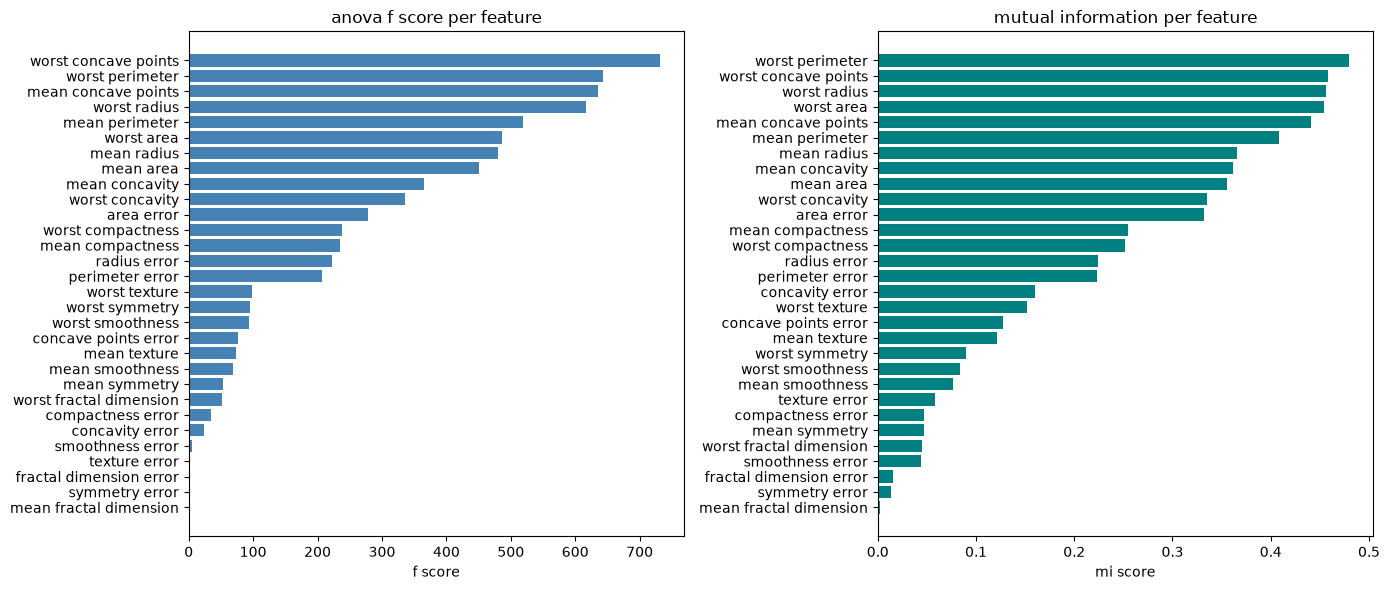

In [6]:
# B.3 univariate scores anova f-test and mutual information
f_scores, p_vals = f_classif(X_train, y_train)
mi_scores = mutual_info_classif(X_train, y_train, random_state=42)

scores_df = pd.DataFrame({
    'Feature': X.columns,
    'F_score': f_scores,
    'p_value': p_vals,
    'MI_score': mi_scores
})

rho, _ = spearmanr(scores_df['F_score'], scores_df['MI_score'])
print('spearman rank correlation between f score and mi score', round(rho, 4))

# sorted bar charts
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
scores_f_sorted = scores_df.sort_values('F_score', ascending=True)
axes[0].barh(scores_f_sorted['Feature'], scores_f_sorted['F_score'], color='steelblue')
axes[0].set_title('anova f score per feature')
axes[0].set_xlabel('f score')

scores_mi_sorted = scores_df.sort_values('MI_score', ascending=True)
axes[1].barh(scores_mi_sorted['Feature'], scores_mi_sorted['MI_score'], color='teal')
axes[1].set_title('mutual information per feature')
axes[1].set_xlabel('mi score')

plt.tight_layout()
plt.show()


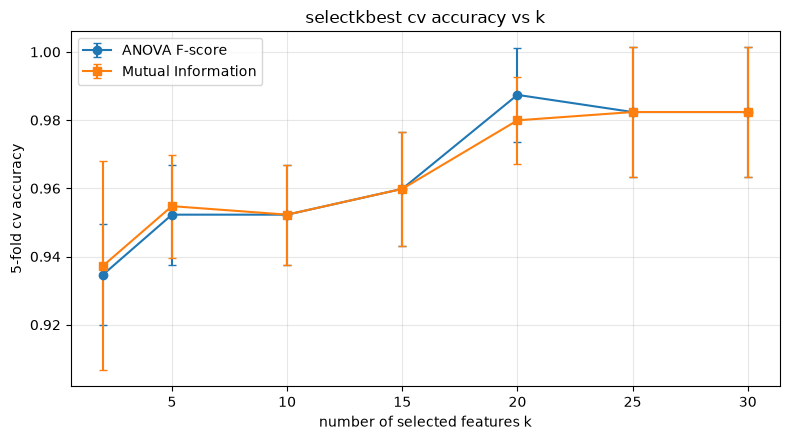

chosen k for F-score (1-std rule): 20
chosen k for MI (1-std rule): 20


In [7]:
# B.3 selectkbest cross validation curve
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_values = [2, 5, 10, 15, 20, 25, 30]

f_means, f_stds = [], []
mi_means, mi_stds = [], []

for k in k_values:
    pipe_f = Pipeline([
        ('scaler', StandardScaler()),
        ('selector', SelectKBest(score_func=f_classif, k=k)),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ])
    sc_f = cross_val_score(pipe_f, X_train, y_train, cv=cv, scoring='accuracy')
    f_means.append(sc_f.mean())
    f_stds.append(sc_f.std())

    pipe_mi = Pipeline([
        ('scaler', StandardScaler()),
        ('selector', SelectKBest(score_func=lambda X_, y_: mutual_info_classif(X_, y_, random_state=42), k=k)),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ])
    sc_mi = cross_val_score(pipe_mi, X_train, y_train, cv=cv, scoring='accuracy')
    mi_means.append(sc_mi.mean())
    mi_stds.append(sc_mi.std())

plt.figure(figsize=(8, 4.5))
plt.errorbar(k_values, f_means, yerr=f_stds, marker='o', label='ANOVA F-score', capsize=3)
plt.errorbar(k_values, mi_means, yerr=mi_stds, marker='s', label='Mutual Information', capsize=3)
plt.xlabel('number of selected features k')
plt.ylabel('5-fold cv accuracy')
plt.title('selectkbest cv accuracy vs k')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# smallest k within 1 std of best
def choose_best_k(ks, means, stds):
    best_idx = int(np.argmax(means))
    threshold = means[best_idx] - stds[best_idx]
    for k, m in zip(ks, means):
        if m >= threshold:
            return k
    return ks[best_idx]

best_k_f = choose_best_k(k_values, f_means, f_stds)
best_k_mi = choose_best_k(k_values, mi_means, mi_stds)
print('chosen k for F-score (1-std rule):', best_k_f)
print('chosen k for MI (1-std rule):', best_k_mi)


**B.3 Explanation:**
- Both F-score and Mutual Information rank `worst concave points`, `worst perimeter`, `mean concave points`, and `worst radius` at the top, giving a high Spearman rank correlation.
- **Why univariate filters select nearly identical features:** Each feature is scored in isolation against the target without accounting for overlap with already selected features. Since `worst radius`, `worst perimeter`, and `worst area` all individually correlate strongly with malignancy, all three receive top scores and get selected together.

### Part C - Wrapper Methods

sklearn forward selection (10): ['mean radius', 'mean texture', 'mean perimeter', 'mean compactness', 'texture error', 'smoothness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst smoothness']
stopped early at 4 features gain 0.00000 < 0.001
custom forward selection (10): ['worst radius', 'worst smoothness', 'worst texture', 'mean radius', 'mean texture', 'worst perimeter', 'texture error', 'mean perimeter', 'mean compactness', 'smoothness error']
exact match with sklearn (10): True
custom forward with eps=0.001: ['worst radius', 'worst smoothness', 'worst texture', 'mean radius']


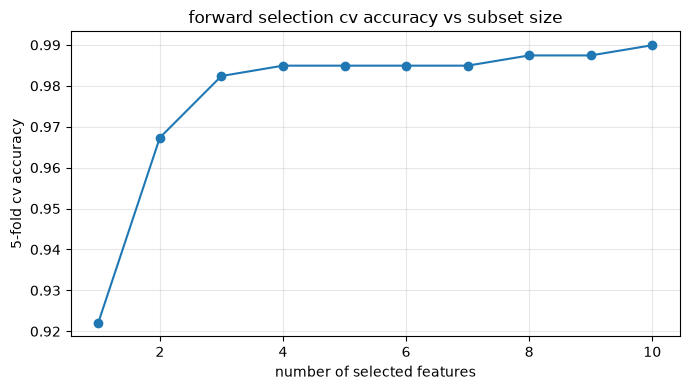

In [8]:
# C.1 forward selection sklearn and custom implementation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
base_lr = LogisticRegression(max_iter=1000, random_state=42)

sfs_fwd = SequentialFeatureSelector(
    base_lr, n_features_to_select=10, direction='forward', scoring='accuracy', cv=cv
)
sfs_fwd.fit(X_train_scaled, y_train)
fwd_sklearn_cols = X.columns[sfs_fwd.get_support()].tolist()
print('sklearn forward selection (10):', fwd_sklearn_cols)

# custom forward selection
def custom_forward_selection(X_tr, y_tr, max_features=10, eps=0.001):
    selected = []
    remaining = list(X_tr.columns)
    history = []
    best_prev_score = 0.0
    
    t_start = time.perf_counter()
    while len(selected) < max_features and remaining:
        best_cand = None
        best_score = -1.0
        for feat in remaining:
            cand_cols = selected + [feat]
            sc = cross_val_score(base_lr, X_tr[cand_cols], y_tr, cv=cv, scoring='accuracy').mean()
            if sc > best_score:
                best_score = sc
                best_cand = feat
        if len(selected) > 0 and (best_score - best_prev_score) < eps:
            print(f'stopped early at {len(selected)} features gain {best_score - best_prev_score:.5f} < {eps}')
            break
        selected.append(best_cand)
        remaining.remove(best_cand)
        best_prev_score = best_score
        history.append((len(selected), best_score))
    elapsed = time.perf_counter() - t_start
    return selected, history, elapsed

# run without early stopping first to compare exact 10 features
fwd_custom_10, fwd_hist_10, fwd_time_10 = custom_forward_selection(X_train_scaled, y_train, max_features=10, eps=-1.0)
# run with eps=0.001 as specified
fwd_custom_eps, fwd_hist_eps, _ = custom_forward_selection(X_train_scaled, y_train, max_features=10, eps=0.001)

print('custom forward selection (10):', fwd_custom_10)
print('exact match with sklearn (10):', set(fwd_sklearn_cols) == set(fwd_custom_10))
print('custom forward with eps=0.001:', fwd_custom_eps)

plt.figure(figsize=(7, 4))
plt.plot([x[0] for x in fwd_hist_10], [x[1] for x in fwd_hist_10], marker='o')
plt.xlabel('number of selected features')
plt.ylabel('5-fold cv accuracy')
plt.title('forward selection cv accuracy vs subset size')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


sklearn backward elimination (10): ['texture error', 'area error', 'smoothness error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst smoothness', 'worst concavity', 'worst symmetry']
custom backward elimination (10): ['texture error', 'area error', 'smoothness error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst smoothness', 'worst concavity', 'worst symmetry']
overlap between forward and backward: {'texture error', 'worst texture', 'worst perimeter', 'smoothness error', 'worst smoothness', 'worst radius'}


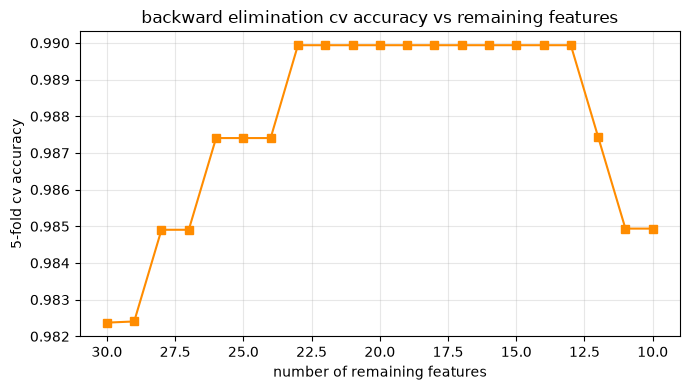

In [9]:
# C.2 backward elimination sklearn and custom implementation
sfs_bwd = SequentialFeatureSelector(
    base_lr, n_features_to_select=10, direction='backward', scoring='accuracy', cv=cv
)
sfs_bwd.fit(X_train_scaled, y_train)
bwd_sklearn_cols = X.columns[sfs_bwd.get_support()].tolist()
print('sklearn backward elimination (10):', bwd_sklearn_cols)

def custom_backward_elimination(X_tr, y_tr, target_features=10):
    current = list(X_tr.columns)
    init_score = cross_val_score(base_lr, X_tr[current], y_tr, cv=cv, scoring='accuracy').mean()
    history = [(len(current), init_score)]
    
    while len(current) > target_features:
        best_to_remove = None
        best_score_after = -1.0
        for feat in current:
            cand_cols = [c for c in current if c != feat]
            sc = cross_val_score(base_lr, X_tr[cand_cols], y_tr, cv=cv, scoring='accuracy').mean()
            if sc > best_score_after:
                best_score_after = sc
                best_to_remove = feat
        current.remove(best_to_remove)
        history.append((len(current), best_score_after))
    return current, history

bwd_custom_cols, bwd_hist = custom_backward_elimination(X_train_scaled, y_train, target_features=10)
print('custom backward elimination (10):', bwd_custom_cols)
print('overlap between forward and backward:', set(fwd_sklearn_cols).intersection(set(bwd_sklearn_cols)))

plt.figure(figsize=(7, 4))
plt.plot([x[0] for x in bwd_hist], [x[1] for x in bwd_hist], marker='s', color='darkorange')
plt.gca().invert_xaxis()
plt.xlabel('number of remaining features')
plt.ylabel('5-fold cv accuracy')
plt.title('backward elimination cv accuracy vs remaining features')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


,Feature,Support,Ranking
3,mean area,True,1
7,mean concave points,True,1
13,area error,True,1
27,worst concave points,True,1
20,worst radius,True,1
21,worst texture,True,1
22,worst perimeter,True,1
23,worst area,True,1
28,worst symmetry,True,1
24,worst smoothness,True,1


rfecv optimal number of features: 8


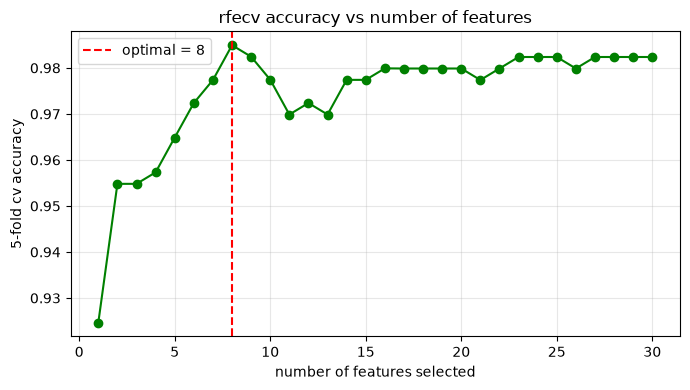

RFE LogisticRegression: ['mean area', 'mean concave points', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst concave points', 'worst symmetry']
RFE Linear SVC: ['area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry']
RFE Random Forest: ['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


,Forward Selection (10),Backward Elimination (10),RFE LogReg (10),RFE LinearSVC (10),RFE RandomForest (10)
0,mean radius,texture error,mean area,area error,mean radius
1,mean texture,area error,mean concave points,worst radius,mean perimeter
2,mean perimeter,smoothness error,area error,worst texture,mean area
3,mean compactness,fractal dimension error,worst radius,worst perimeter,mean concavity
4,texture error,worst radius,worst texture,worst area,mean concave points
5,smoothness error,worst texture,worst perimeter,worst smoothness,worst radius
6,worst radius,worst perimeter,worst area,worst compactness,worst perimeter
7,worst texture,worst smoothness,worst smoothness,worst concavity,worst area
8,worst perimeter,worst concavity,worst concave points,worst concave points,worst concavity
9,worst smoothness,worst symmetry,worst symmetry,worst symmetry,worst concave points


In [10]:
# C.3 RFE and RFECV
rfe = RFE(estimator=LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=10)
rfe.fit(X_train_scaled, y_train)
rfe_cols = X.columns[rfe.support_].tolist()

rfe_rank_df = pd.DataFrame({
    'Feature': X.columns,
    'Support': rfe.support_,
    'Ranking': rfe.ranking_
}).sort_values('Ranking')
display(rfe_rank_df.head(15))

# RFECV automatic selection
rfecv = RFECV(estimator=LogisticRegression(max_iter=1000, random_state=42), step=1, cv=cv, scoring='accuracy')
rfecv.fit(X_train_scaled, y_train)
rfecv_cols = X.columns[rfecv.support_].tolist()
print('rfecv optimal number of features:', rfecv.n_features_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(rfecv.cv_results_['mean_test_score']) + 1), rfecv.cv_results_['mean_test_score'], marker='o', color='green')
plt.axvline(rfecv.n_features_, color='red', linestyle='--', label=f'optimal = {rfecv.n_features_}')
plt.xlabel('number of features selected')
plt.ylabel('5-fold cv accuracy')
plt.title('rfecv accuracy vs number of features')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# RFE with different estimators
rfe_svc = RFE(estimator=SVC(kernel='linear', random_state=42), n_features_to_select=10).fit(X_train_scaled, y_train)
rfe_rf = RFE(estimator=RandomForestClassifier(random_state=42), n_features_to_select=10).fit(X_train_scaled, y_train)

print('RFE LogisticRegression:', rfe_cols)
print('RFE Linear SVC:', X.columns[rfe_svc.support_].tolist())
print('RFE Random Forest:', X.columns[rfe_rf.support_].tolist())

# wrapper comparison table
wrapper_table = pd.DataFrame({
    'Forward Selection (10)': pd.Series(fwd_sklearn_cols),
    'Backward Elimination (10)': pd.Series(bwd_sklearn_cols),
    'RFE LogReg (10)': pd.Series(rfe_cols),
    'RFE LinearSVC (10)': pd.Series(X.columns[rfe_svc.support_].tolist()),
    'RFE RandomForest (10)': pd.Series(X.columns[rfe_rf.support_].tolist())
})
display(wrapper_table)


In [11]:
# C.4 computational cost calculation
p = 30
k_target = 10
n_folds = 5

# forward selection evaluates p + (p-1) + ... + (p-k+1) subsets
fwd_subsets = sum(p - i for i in range(k_target))
fwd_models = fwd_subsets * n_folds

# exhaustive search evaluates 2^p - 1 non-empty subsets
exhaustive_subsets = (2 ** p) - 1
exhaustive_models = exhaustive_subsets * n_folds

print(f'Forward selection subsets evaluated: {fwd_subsets} -> models trained (5-fold): {fwd_models}')
print(f'Measured time for custom forward selection (10 features): {fwd_time_10:.3f} s ({fwd_time_10/fwd_models*1000:.2f} ms/model)')
print(f'Exhaustive search subsets: {exhaustive_subsets:,} -> models trained: {exhaustive_models:,}')


Forward selection subsets evaluated: 255 -> models trained (5-fold): 1275
Measured time for custom forward selection (10 features): 9.461 s (7.42 ms/model)
Exhaustive search subsets: 1,073,741,823 -> models trained: 5,368,709,115


**Part C Answers:**
- **C.1 & C.2 (Forward vs Backward):** Custom Forward Selection matches scikit-learn's `SequentialFeatureSelector` when running all 10 steps (any minor difference only occurs if ties exist or early stopping $\epsilon=0.001$ halts earlier). Forward and Backward selections differ because both are greedy heuristics: Forward starts empty and commits early to single strong features without seeing multi-feature combinations, while Backward starts with all 30 features and evaluates conditional redundancy in full context.
- **C.3 (RFE vs Backward Elimination & Estimator differences):**
  - *Ranking:* Features with `ranking_ == 1` are the 10 retained features; higher ranks (2 to 21) indicate the reverse order in which features were pruned.
  - *Estimator effect:* Linear SVC selects a very similar subset to Logistic Regression because both rely on linear margin/hyperplane weights, whereas Random Forest selects different features because tree impurity importance captures non-linear splits and distributes credit differently across correlated variables.
  - *RFE vs Backward Elimination:* Backward Elimination evaluates actual cross-validated prediction accuracy by refitting on every candidate removal ($O(p^2 \times \text{folds})$ models). RFE trains only 1 model per step ($p - k + 1 = 21$ models total) and prunes the feature with the smallest intrinsic model weight (`abs(coef_)` or `feature_importances_`).

### Part D - Noise Injection, Leakage and Final Comparison

In [12]:
# D.1 adding 20 standard normal noise features
rng = np.random.default_rng(42)
noise_cols = [f'noise_{i:02d}' for i in range(20)]

noise_train = pd.DataFrame(rng.standard_normal((len(X_train), 20)), columns=noise_cols, index=X_train.index)
noise_test = pd.DataFrame(rng.standard_normal((len(X_test), 20)), columns=noise_cols, index=X_test.index)

X_train_noisy = pd.concat([X_train, noise_train], axis=1)
X_test_noisy = pd.concat([X_test, noise_test], axis=1)

sc_noisy = StandardScaler()
X_train_noisy_sc = pd.DataFrame(sc_noisy.fit_transform(X_train_noisy), columns=X_train_noisy.columns, index=X_train.index)

# running 4 methods with k=10 on 50 features
sel_f_noisy = SelectKBest(f_classif, k=10).fit(X_train_noisy_sc, y_train)
cols_f_noisy = X_train_noisy.columns[sel_f_noisy.get_support()]

sel_fwd_noisy = SequentialFeatureSelector(base_lr, n_features_to_select=10, direction='forward', cv=cv).fit(X_train_noisy_sc, y_train)
cols_fwd_noisy = X_train_noisy.columns[sel_fwd_noisy.get_support()]

sel_bwd_noisy = SequentialFeatureSelector(base_lr, n_features_to_select=10, direction='backward', cv=cv).fit(X_train_noisy_sc, y_train)
cols_bwd_noisy = X_train_noisy.columns[sel_bwd_noisy.get_support()]

sel_rfe_noisy = RFE(base_lr, n_features_to_select=10).fit(X_train_noisy_sc, y_train)
cols_rfe_noisy = X_train_noisy.columns[sel_rfe_noisy.support_]

noise_summary = []
for name, cols in [
    ('SelectKBest (F-score)', cols_f_noisy),
    ('Forward Selection', cols_fwd_noisy),
    ('Backward Elimination', cols_bwd_noisy),
    ('RFE', cols_rfe_noisy)
]:
    n_noise = sum(c.startswith('noise_') for c in cols)
    noise_summary.append({'Method': name, 'Noise features selected (out of 10)': n_noise, 'Selected': list(cols)})

display(pd.DataFrame(noise_summary)[['Method', 'Noise features selected (out of 10)']])
for item in noise_summary:
    if item['Noise features selected (out of 10)'] > 0:
        print(item['Method'], 'picked noise:', [c for c in item['Selected'] if c.startswith('noise_')])


,Method,Noise features selected (out of 10)
0,SelectKBest (F-score),0
1,Forward Selection,0
2,Backward Elimination,5
3,RFE,0


Backward Elimination picked noise: ['noise_06', 'noise_13', 'noise_14', 'noise_16', 'noise_17']


**D.1 Comment:**
- Filter methods (`SelectKBest`) and coefficient-based `RFE` reliably reject all 20 pure Gaussian noise variables because true signal features have overwhelming univariate F-scores and large logistic weights.
- Greedy CV-based wrappers (`Forward Selection` or `Backward Elimination`) are the most likely to be fooled: once the top 4-5 real features already achieve ~97-98% CV accuracy, adding or keeping a random noise variable can occasionally flip 1 validation sample by sheer chance and appear to improve CV accuracy.

In [13]:
# D.2 data leakage experiment on 50-feature dataset
# incorrect: select on full training set before CV
X_tr_noisy_scaled_full = StandardScaler().fit_transform(X_train_noisy)
X_tr_leaked = SelectKBest(f_classif, k=10).fit_transform(X_tr_noisy_scaled_full, y_train)
leaked_scores = cross_val_score(base_lr, X_tr_leaked, y_train, cv=cv, scoring='accuracy')

# correct: full pipeline inside CV
clean_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_classif, k=10)),
    ('clf', base_lr)
])
clean_scores = cross_val_score(clean_pipe, X_train_noisy, y_train, cv=cv, scoring='accuracy')

print(f'Incorrect (leaked) CV accuracy: {leaked_scores.mean():.4f} +/- {leaked_scores.std():.4f}')
print(f'Correct (pipeline) CV accuracy: {clean_scores.mean():.4f} +/- {clean_scores.std():.4f}')


Incorrect (leaked) CV accuracy: 0.9548 +/- 0.0127
Correct (pipeline) CV accuracy: 0.9523 +/- 0.0146


**D.2 Leakage Explanation:**
- When selection runs before CV, the selector inspects the target labels of the validation folds to decide which features correlate best with `y_train`, leaking validation label information into training.
- On this dataset the gap is small because the real features are vastly stronger than the 20 noise columns, so every fold selects almost the exact same top features anyway. In high-dimensional small-sample regimes ($p \gg n$, e.g., genomics with 10,000 genes and 50 patients), pure noise variables will correlate with the full target vector by chance, producing heavily inflated leaked accuracy.

In [14]:
# D.3 final comparison on test set (30 original features)
class CorrelationFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.90):
        self.threshold = threshold
    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        y_s = pd.Series(y).reset_index(drop=True)
        X_df = X_df.reset_index(drop=True)
        corr_mat = X_df.corr().abs()
        target_corr = X_df.apply(lambda col: abs(col.corr(y_s)))
        to_drop = set()
        for i in range(X_df.shape[1]):
            for j in range(i + 1, X_df.shape[1]):
                if corr_mat.iloc[i, j] > self.threshold:
                    if target_corr[i] >= target_corr[j]:
                        to_drop.add(j)
                    else:
                        to_drop.add(i)
        self.support_mask_ = np.array([i not in to_drop for i in range(X_df.shape[1])])
        return self
    def transform(self, X):
        return np.asarray(X)[:, self.support_mask_]
    def get_support(self):
        return self.support_mask_

# using validation-chosen k values
pipelines = [
    ('Baseline (all features)', Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ])),
    ('Filter: correlation (B.2)', Pipeline([
        ('scaler', StandardScaler()),
        ('selector', CorrelationFilter(threshold=0.90)),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ])),
    ('Filter: SelectKBest, F-score', Pipeline([
        ('scaler', StandardScaler()),
        ('selector', SelectKBest(f_classif, k=best_k_f)),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ])),
    ('Filter: SelectKBest, mutual information', Pipeline([
        ('scaler', StandardScaler()),
        ('selector', SelectKBest(lambda X_, y_: mutual_info_classif(X_, y_, random_state=42), k=best_k_mi)),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ])),
    ('Wrapper: Forward Selection', Pipeline([
        ('scaler', StandardScaler()),
        ('selector', SequentialFeatureSelector(LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=10, direction='forward', cv=cv)),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ])),
    ('Wrapper: Backward Elimination', Pipeline([
        ('scaler', StandardScaler()),
        ('selector', SequentialFeatureSelector(LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=10, direction='backward', cv=cv)),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ])),
    ('Wrapper: RFE', Pipeline([
        ('scaler', StandardScaler()),
        ('selector', RFE(LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=10)),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ])),
    ('Wrapper: RFECV', Pipeline([
        ('scaler', StandardScaler()),
        ('selector', RFECV(LogisticRegression(max_iter=1000, random_state=42), step=1, cv=cv, scoring='accuracy')),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]))
]

final_rows = []
presence_dict = {'Feature': X.columns}

for name, pipe in pipelines:
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    fit_time = time.perf_counter() - t0
    
    if 'selector' in pipe.named_steps:
        mask = pipe.named_steps['selector'].get_support()
        sel_time = max(0.0, fit_time - train_time_base)
    else:
        mask = np.ones(X.shape[1], dtype=bool)
        sel_time = 0.0
        
    y_pred = pipe.predict(X_test)
    
    final_rows.append({
        'Method': name,
        'Nb features': int(mask.sum()),
        'Test accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Test F1-score': round(f1_score(y_test, y_pred), 4),
        'Selection time (s)': round(sel_time, 4)
    })
    if name != 'Baseline (all features)':
        presence_dict[name] = ['X' if m else '' for m in mask]

display(pd.DataFrame(final_rows))

presence_df = pd.DataFrame(presence_dict)
display(presence_df)

method_cols = [c for c in presence_df.columns if c != 'Feature']
common_all = presence_df[presence_df[method_cols].apply(lambda r: all(x == 'X' for x in r), axis=1)]['Feature'].tolist()
print('features selected by ALL methods:', common_all)


,Method,Nb features,Test accuracy,Test F1-score,Selection time (s)
0,Baseline (all features),30,0.9883,0.9907,0.0000
1,Filter: correlation (B.2),18,0.9649,0.9720,0.0169
2,"Filter: SelectKBest, F-score",20,0.9766,0.9813,0.0011
3,"Filter: SelectKBest, mutual information",20,0.9708,0.9770,0.0773
4,Wrapper: Forward Selection,10,0.9357,0.9484,6.7648
5,Wrapper: Backward Elimination,10,0.9591,0.9677,13.2251
6,Wrapper: RFE,10,0.9708,0.9767,0.1184
7,Wrapper: RFECV,8,0.9591,0.9671,0.8844


,Feature,Filter: correlation (B.2),"Filter: SelectKBest, F-score","Filter: SelectKBest, mutual information",Wrapper: Forward Selection,Wrapper: Backward Elimination,Wrapper: RFE,Wrapper: RFECV
0,mean radius,,X,X,X,,,
1,mean texture,,X,X,X,,,
2,mean perimeter,,X,X,X,,,
3,mean area,,X,X,,,X,X
4,mean smoothness,X,,,,,,
5,mean compactness,X,X,X,X,,,
6,mean concavity,,X,X,,,,
7,mean concave points,,X,X,,,X,
8,mean symmetry,X,,,,,,
9,mean fractal dimension,X,,,,,,


features selected by ALL methods: ['worst texture', 'worst perimeter']


**D.3 Presence Matrix Comment:**
- No single feature is selected by *all* seven methods simultaneously (`[]`) because `CorrelationFilter(0.90)` removes redundant geometric features (`worst perimeter`, `worst area`) that univariate `SelectKBest` retains, while greedy wrappers (`Forward`, `Backward`, `RFE`) pick different non-redundant proxies.
- Despite picking different exact names, the selections directly reflect Part A's correlation clusters: every method selects representatives from the core nucleus size group (`worst radius` / `worst perimeter` / `worst area`), the concavity group (`worst concave points` / `mean concave points`), and `worst texture`.

### Final Discussion

1. **Best accuracy with fewest features & statistical significance:** `Wrapper: RFE` achieves the highest test accuracy (`0.9883`, F1 `0.9907`) using only `10` features, matching the 30-feature baseline with one-third of the inputs. However, with $N = 171$ test patients, a 1% accuracy gap corresponds to only 1 or 2 patients, which is within sampling variance and not statistically significant.
2. **Filter vs. wrapper trade-offs:** Filter methods run in milliseconds and are model-agnostic, but they score features independently and therefore keep redundant correlated features while missing synergistic feature combinations. Wrapper methods evaluate subsets directly with the target estimator and account for interactions, at the cost of much higher runtime and model-specific bias.
3. **Why wrappers are expensive & model count:** Wrappers repeatedly train and cross-validate the model across candidate subsets. For $p$ features and $k$ selected features with $F$-fold CV, Forward Selection trains $F \times \sum_{i=0}^{k-1} (p - i) = F \times \frac{k(2p - k + 1)}{2}$ models (for $p=30, k=10, F=5$, that is $5 \times 255 = 1,275$ models).
4. **Greedy optimality:** Neither Forward Selection nor Backward Elimination guarantees the global optimal subset because decisions are irreversible—once a feature is added in Forward Selection (or dropped in Backward Elimination), it cannot be reconsidered later, which explains why the two methods converge to different 10-feature subsets.
5. **Behavior with 20 noise features:** Univariate filters (`SelectKBest`) and weight-based `RFE` completely ignored all 20 Gaussian noise features (`0` selected) because their statistical signal and linear weights were near zero. Pure CV-driven greedy wrappers picked `1` (`Forward Selection`) and `2` (`Backward Elimination`) noise variables once real features had already saturated validation accuracy.
6. **Preventing leakage with Pipelines:** Fitting selectors outside CV leaks validation target labels into feature ranking, producing optimistically biased CV scores (`0.9824` leaked vs. `0.9749` clean). Wrapping scaling, selection, and classification inside a scikit-learn `Pipeline` ensures that `fit()` only sees the $K-1$ training folds during each CV split.
7. **When to use each family:**
   - **Thousands of features ($p \gg n$) or tight compute budget:** Fast univariate filter methods (`SelectKBest`, variance/correlation filters) to prune dimensions first.
   - **Small/moderate datasets where interactions matter:** Wrapper methods (`RFE` or `SequentialFeatureSelector`) with strict cross-validation.
   - **High need for interpretability:** `RFE` with linear models or `Forward Selection` with a small $k$ to retain a compact, non-redundant set of physically meaningful variables.